# 1. Data Integration

## Import Library dan Load Data

In [1]:
import pandas as pd

In [2]:
df_fake = pd.read_csv('../data/Fake.csv')
df_true = pd.read_csv('../data/True.csv')

print(f"Jumlah data Fake: {df_fake.shape[0]}")
print(f"Jumlah data True: {df_true.shape[0]}")

Jumlah data Fake: 23481
Jumlah data True: 21417


## Pelabelan dan Integrasi Data

In [3]:
df_fake['label'] = 1
df_true['label'] = 0

df_merged = pd.concat([df_fake, df_true], axis=0)

df_final = df_merged.sample(frac=1, random_state=42).reset_index(drop=True)

print("\nDimensi dataset setelah digabung:", df_final.shape)
print("\nDistribusi kelas target:\n", df_final['label'].value_counts())

df_final.head()


Dimensi dataset setelah digabung: (44898, 5)

Distribusi kelas target:
 label
1    23481
0    21417
Name: count, dtype: int64


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",1
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",0
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",0
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",1
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",0


# 2. Exploratory Data Analysis (EDA)

## Pemeriksaan Integritas Data (Missing Values dan Duplicates)

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Missing values per kolom:")
print(df_final.isnull().sum())

total_duplicates = df_final.duplicated().sum()
print(f'\nJumlah baris duplikat: {total_duplicates}')

Missing values per kolom:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Jumlah baris duplikat: 209


## Analisis Distribusi Kelas Target

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11092\4047353019.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='label', data=df_final, palette='Set2')


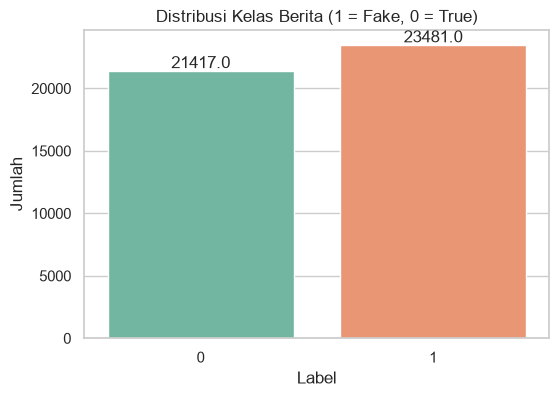

In [5]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='label', data=df_final, palette='Set2')
plt.title('Distribusi Kelas Berita (1 = Fake, 0 = True)')
plt.xlabel('Label')
plt.ylabel('Jumlah')

for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

## Analisis Distribusi Subjek/Kategori

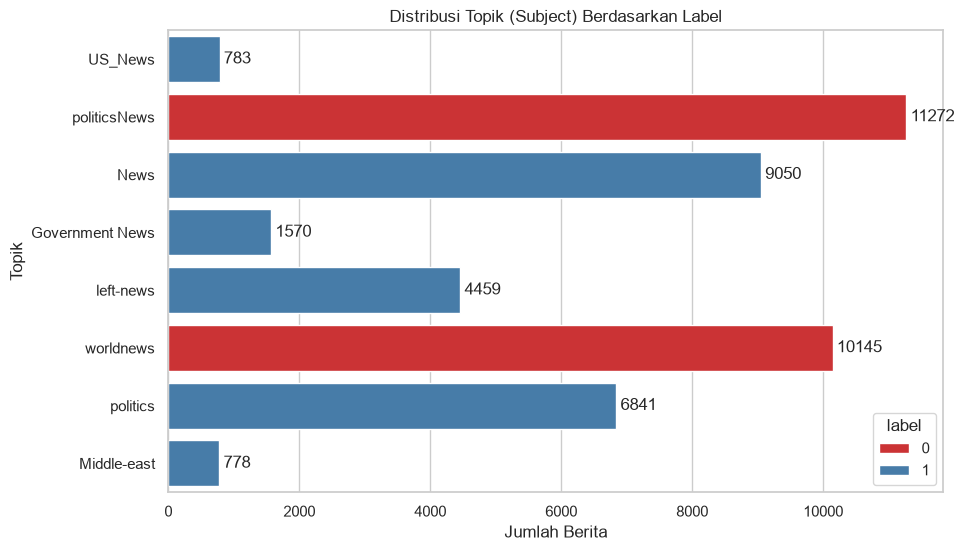

In [8]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(y='subject', hue='label', data=df_final, palette='Set1')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Distribusi Topik (Subject) Berdasarkan Label')
plt.xlabel('Jumlah Berita')
plt.ylabel('Topik')
plt.show()

## Analisis Panjang Teks (Karakter & Kata)

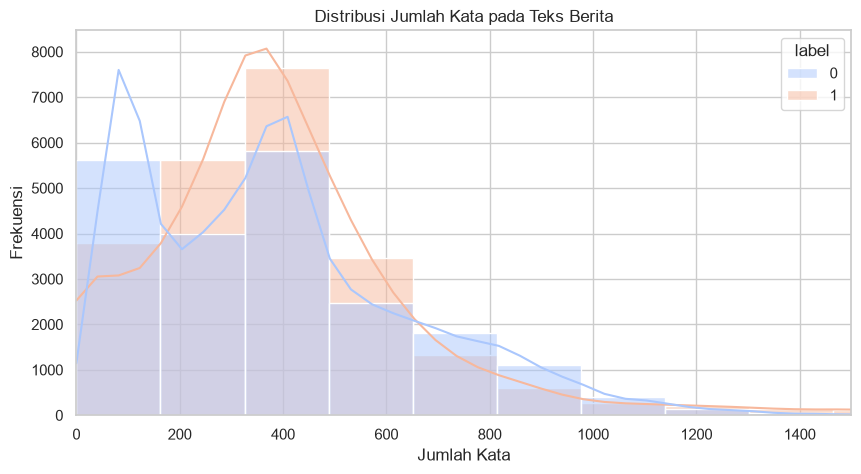

In [10]:
df_final['word_count'] = df_final['text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 5))
sns.histplot(data=df_final, x='word_count', hue='label', bins=50, kde=True, palette='coolwarm')
plt.title('Distribusi Jumlah Kata pada Teks Berita')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.xlim(0, 1500) 
plt.show()

# 3. Feature Selection dan Global Cleaning

## Global Cleaning (Menghapus Duplikat)

In [11]:
df_cleaned = df_final.drop_duplicates(keep='first').reset_index(drop=True)

print(f"Dimensi data sebelum cleaning: {df_final.shape}")
print(f"Dimensi data setelah cleaning: {df_cleaned.shape}")
print(f"Total baris yang dihapus: {df_final.shape[0] - df_cleaned.shape[0]}")

Dimensi data sebelum cleaning: (44898, 6)
Dimensi data setelah cleaning: (44689, 6)
Total baris yang dihapus: 209


## Feature Engineering (Penggabungan Judul dan Teks)

In [12]:
df_cleaned['content'] = df_cleaned['title'] + " " + df_cleaned['text']

print("Sampel kolom 'content':")
print(df_cleaned['content'].iloc[0][:200], "...\n")

Sampel kolom 'content':
Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution 21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame ...



## Feature Selection (Reduksi Dimensi Ideal)

In [15]:
kolom_dihapus = ['title', 'text', 'subject', 'date', 'word_count']

df_model = df_cleaned.drop(columns=kolom_dihapus, errors='ignore')

print("Struktur Data Final untuk Model:")
print(df_model.info())

print("\nDistribusi Kelas Final:")
print(df_model['label'].value_counts())

Struktur Data Final untuk Model:
<class 'pandas.DataFrame'>
RangeIndex: 44689 entries, 0 to 44688
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    44689 non-null  int64
 1   content  44689 non-null  str  
dtypes: int64(1), str(1)
memory usage: 109.7 MB
None

Distribusi Kelas Final:
label
1    23478
0    21211
Name: count, dtype: int64


# 4. Data Splitting

## Pemisahan Variabel Independen (X) dan Dependen (y)

In [16]:
X = df_model['content']
y = df_model['label']

print(f"Dimensi X: {X.shape}")
print(f"Dimensi y: {y.shape}")

Dimensi X: (44689,)
Dimensi y: (44689,)


## Eksekusi Train-Test Split dengan Stratifikasi

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("=== Dimensi Data ===")
print(f"X_train: {X_train.shape[0]} sampel")
print(f"X_test: {X_test.shape[0]} sampel\n")

print("=== Proporsi Kelas Data Latih (y_train) ===")
print(y_train.value_counts(normalize=True))

print("\n=== Proporsi Kelas Data Uji (y_test) ===")
print(y_test.value_counts(normalize=True))

=== Dimensi Data ===
X_train: 35751 sampel
X_test: 8938 sampel

=== Proporsi Kelas Data Latih (y_train) ===
label
1    0.525356
0    0.474644
Name: proportion, dtype: float64

=== Proporsi Kelas Data Uji (y_test) ===
label
1    0.525397
0    0.474603
Name: proportion, dtype: float64


# 5. Text Preprocessing

## Inisialisasi Komponen NLTK dan Fungsi Pembersihan

In [20]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')

stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    
    text = re.sub(r'[^a-z\s]', '', text)
    
    words = text.split()
    cleaned_words = [stemmer.stem(word) for word in words if word not in stop_words]
    
    return ' '.join(cleaned_words)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


## Menerapkan Pembersihan pada Data Latih dan Uji

In [22]:
import time

print("Memulai preprocessing pada X_train...")
start_time = time.time()
X_train_clean = X_train.apply(preprocess_text)
print(f"Selesai dalam {time.time() - start_time:.2f} detik.")

print("\nMemulai preprocessing pada X_test...")
start_time = time.time()
X_test_clean = X_test.apply(preprocess_text)
print(f"Selesai dalam {time.time() - start_time:.2f} detik.")

print("\n=== Perbandingan Teks (Sebelum vs Sesudah) ===")
print("Asli   :", X_train.iloc[0][:150], "...")
print("Bersih :", X_train_clean.iloc[0][:150], "...")

Memulai preprocessing pada X_train...
Selesai dalam 112.00 detik.

Memulai preprocessing pada X_test...
Selesai dalam 25.77 detik.

=== Perbandingan Teks (Sebelum vs Sesudah) ===
Asli   : JUDICIAL WATCH INVESTIGATOR: Here’s why we’re becoming a ‘FAILED STATE’ [Video] Chris Farrell is the Judicial Watch Director of Investigations who let ...
Bersih : judici watch investig here becom fail state video chri farrel judici watch director investig let rip last night direct america go lou dobb got ear far ...
